# Week 3 Model Development and Experimentation

**Project:** Predicting early (< 30 days) hospital readmission of diabetic patients – Diabetes 130-US Hospitals (UCI).
**Plan followed:** [`Week_1/project_specification.pdf`](../Week_1/project_specification.pdf), sections 3 and 6–8. **Starting point:** [`Week_2`](../Week_2/week2_data_preparation_baseline.ipynb) (clean dataset, patient-grouped folds, baseline).

Week 3 objectives (from the project timeline) and where they are covered:

| Timeline objective | Section |
| --- | --- |
| Select and implement one or more Machine Learning models | 2 |
| Train and evaluate the models | 3, 4 |
| Experiment with feature selection and hyperparameter tuning | 3 (tuning), 6 (feature selection) |
| Compare results against the baseline | 4, 5 |
| Analyse errors and identify potential limitations | 7, 8 |

**Deliverable:** experimental results and comparison with the baseline – this notebook and the tables in `Week_3/outputs/`.

### Rules kept from week 2

* **Same data, same folds.** The saved `split` and `fold` columns are reused, so every model is compared with the baseline on identical patients. **The test set is not used** (week 4).
* **Everything learned stays inside the training folds**: imputation, scaling, encoding, hyperparameters *and* feature selection.
* **Main metric: PR-AUC**, chance level = prevalence (0.114). The operational view is precision / recall on the 20 % highest-risk encounters.

New risks this week:

| Risk | Safeguard |
| --- | --- |
| Choosing hyperparameters on the folds used to report the score (optimistic bias) | **Nested** cross-validation (section 3) |
| Selecting features with the validation fold | Selection is repeated inside each outer training set (section 6) |
| Early stopping on a random split that separates encounters of one patient | `early_stopping=False`; the number of trees is tuned instead |
| Declaring a winner from noise | Paired comparison on the same folds, with a test corrected for overlapping training sets (section 5) |

In [1]:
import itertools
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from joblib import Parallel, delayed
from scipy import stats
from sklearn import set_config
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    f1_score,
    mutual_info_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import ParameterGrid, ParameterSampler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# L1 is written l1_ratio=1 (scikit-learn >= 1.8); older versions would silently fit L2 instead
assert tuple(map(int, sklearn.__version__.split(".")[:2])) >= (1, 8), "scikit-learn >= 1.8 required"

SEED = 42
TOP_FRACTION = 0.20  # follow-up capacity, same as week 2

set_config(display="diagram")
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 160)

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.grid": True, "grid.color": "#e6e5e0",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.labelcolor": GRAY, "xtick.color": GRAY, "ytick.color": GRAY,
})

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "diabetic_data.csv").is_file())
W2 = ROOT / "Week_2" / "outputs"
OUT_DIR = ROOT / "Week_3" / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.8.0


## 1. Reload the week-2 data and check the baseline

Only the training rows are kept. We recompute the week-2 logistic regression and check that it gives the saved numbers: if it does, data, folds, preprocessing and metrics are the same as in week 2.

In [2]:
config = json.loads((W2 / "feature_config.json").read_text(encoding="utf-8"))
NUMERIC, CATEGORICAL = config["numeric"], config["categorical"]
FEATURES = NUMERIC + CATEGORICAL

data = pd.read_csv(W2 / "diabetic_clean.csv.gz", dtype={c: "object" for c in CATEGORICAL})
train = data[data["split"] == "train"].reset_index(drop=True)
del data  # the test rows are not kept in memory

X, y, folds = train[FEATURES], train["target"].to_numpy(), train["fold"].to_numpy()
FOLDS = np.unique(folds)
prevalence = y.mean()

assert train.groupby("patient_nbr")["fold"].nunique().max() == 1, "patient in several folds"
assert not {"encounter_id", "patient_nbr", "readmitted", "target", "fold"} & set(FEATURES)
print(f"{len(train):,} training encounters, {train['patient_nbr'].nunique():,} patients, "
      f"{len(FEATURES)} features, prevalence {prevalence:.3f}")


def make_preprocess(features=FEATURES):
    # Week-2 preprocessing, restricted to a list of variables
    numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    categorical_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False)),
    ])
    return ColumnTransformer([("num", numeric_pipe, [c for c in features if c in NUMERIC]),
                              ("cat", categorical_pipe, [c for c in features if c in CATEGORICAL])])


def make_model(clf, features=FEATURES):
    return Pipeline([("prep", make_preprocess(features)), ("clf", clf)])


def top_flags(scores, fraction=TOP_FRACTION):
    flagged = np.zeros(len(scores), dtype=bool)
    flagged[np.argsort(-scores, kind="stable")[:int(np.ceil(fraction * len(scores)))]] = True
    return flagged


def flag_per_fold(scores):
    out = np.zeros(len(scores), dtype=bool)
    for f in FOLDS:
        out[folds == f] = top_flags(scores[folds == f])
    return out


def compute_metrics(y_true, p):
    pred, flagged = (p >= 0.5).astype(int), top_flags(p)
    return {
        "PR-AUC": average_precision_score(y_true, p),
        "ROC-AUC": roc_auc_score(y_true, p),
        "Precision@20%": y_true[flagged].mean(),
        "Recall@20%": y_true[flagged].sum() / y_true.sum(),
        "Accuracy": accuracy_score(y_true, pred),
        "Balanced acc.": balanced_accuracy_score(y_true, pred),
        "Precision@0.5": precision_score(y_true, pred, zero_division=0),
        "Recall@0.5": recall_score(y_true, pred),
        "F1@0.5": f1_score(y_true, pred, zero_division=0),
    }


def evaluate_cv(model_for_fold, y=y):
    # model_for_fold: fold -> unfitted pipeline. Returns per-fold metrics, out-of-fold and training scores
    rows, oof, in_fold = [], np.full(len(y), np.nan), {}
    for fold in FOLDS:
        tr, va = folds != fold, folds == fold
        start = time.perf_counter()
        fitted = model_for_fold(fold).fit(X[tr], y[tr])
        seconds = time.perf_counter() - start
        oof[va] = fitted.predict_proba(X[va])[:, 1]
        in_fold[fold] = fitted.predict_proba(X[tr])[:, 1]
        rows.append({"fold": fold, **compute_metrics(y[va], oof[va]),
                     "Train PR-AUC": average_precision_score(y[tr], in_fold[fold]), "Fit time (s)": seconds})
    return pd.DataFrame(rows).set_index("fold"), oof, in_fold


BASELINE = "LR baseline (week 2)"
baseline_clf = LogisticRegression(class_weight="balanced", max_iter=3000, random_state=SEED)
results, oof_scores, train_scores = {}, {}, {}
results[BASELINE], oof_scores[BASELINE], train_scores[BASELINE] = evaluate_cv(lambda f: make_model(clone(baseline_clf)))

saved = pd.read_csv(W2 / "baseline_cv_results.csv", header=[0, 1], index_col=0)["Logistic regression (balanced)"]["mean"]
check = pd.DataFrame({"week 2": saved, "recomputed": results[BASELINE].mean()}).dropna()
display(check.round(4))
assert np.allclose(check["week 2"], check["recomputed"], atol=1e-3), "baseline not reproduced"
print("Week-2 baseline reproduced.")

79,541 training encounters, 55,992 patients, 43 features, prevalence 0.114


,week 2,recomputed
Accuracy,0.6681,0.6681
Balanced acc.,0.6159,0.6159
F1@0.5,0.2743,0.2743
PR-AUC,0.2144,0.2144
Precision@0.5,0.1829,0.1829
Precision@20%,0.2149,0.2149
ROC-AUC,0.6629,0.6629
Recall@0.5,0.5483,0.5483
Recall@20%,0.3758,0.3758
Train PR-AUC,0.2206,0.2206


Week-2 baseline reproduced.


## 2. Models

| Model | Why | What it can do that the baseline cannot |
| --- | --- | --- |
| **Logistic regression, L2, tuned `C`** | The baseline used the default `C = 1`; a fair comparison needs a tuned baseline | Nothing new: isolates the effect of tuning |
| **Logistic regression, L1** | Sets useless coefficients to zero (embedded selection) | Sparse model |
| **Random forest** (bagging; Breiman, 2001) | Averages many decorrelated trees, reduces variance | Non-linearities and interactions |
| **Histogram gradient boosting** (Friedman, 2001; Ke et al., 2017) | Trees are added one by one to correct the previous errors; usually strong on tabular data | Same, with lower bias |
| **Soft-voting ensemble** | Mean probability of the L1, forest and boosting models | Can average out errors that differ between families |

All models use the week-2 preprocessing and `class_weight="balanced"`, so differences come from the algorithm only (the weighting is examined in section 4.3).

Kernel SVM and k-NN are not included: an RBF SVM scales badly to about 64,000 rows, and distances are not very meaningful in about 200 mostly binary columns.

In [3]:
CLASSIFIERS = {
    "LR L2 (tuned)": LogisticRegression(class_weight="balanced", max_iter=3000, random_state=SEED),
    "LR L1 (tuned)": LogisticRegression(solver="liblinear", l1_ratio=1, class_weight="balanced",
                                        max_iter=1000, random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=SEED),
    "Gradient boosting": HistGradientBoostingClassifier(class_weight="balanced", early_stopping=False,
                                                        random_state=SEED),
}

C_GRID = list(ParameterGrid({"C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]}))
SEARCH_SPACE = {
    "LR L2 (tuned)": C_GRID,
    "LR L1 (tuned)": C_GRID,
    "Random forest": list(ParameterSampler({
        "min_samples_leaf": [5, 10, 20, 50, 100],
        "max_features": ["sqrt", 0.1, 0.2, 0.3],
        "max_depth": [None, 12, 20],
    }, n_iter=12, random_state=SEED)),
    "Gradient boosting": list(ParameterSampler({
        "learning_rate": [0.02, 0.05, 0.1],
        "max_iter": [100, 200, 400],
        "max_leaf_nodes": [7, 15, 31],
        "min_samples_leaf": [20, 50, 100, 200],
        "l2_regularization": [0.0, 1.0, 10.0],
        "max_features": [0.3, 0.6, 1.0],
    }, n_iter=20, random_state=SEED)),
}
for name, space in SEARCH_SPACE.items():
    print(f"{name}: {len(space)} configurations")

LR L2 (tuned): 7 configurations
LR L1 (tuned): 7 configurations
Random forest: 12 configurations
Gradient boosting: 20 configurations


## 3. Hyperparameter tuning (nested cross-validation)

If we tuned on the 5 folds and reported the best score on those same folds, the score would be optimistic. We therefore use two levels:

* **Outer level**: the 5 week-2 folds. Each gives the reported score.
* **Inner level**: for outer fold *i*, every configuration is trained on 3 of the 4 remaining folds and scored on the 4th, for the 4 possible choices. The configuration with the best mean inner PR-AUC is refitted on the 4 folds and evaluated **once** on fold *i*.

Fold *i* therefore never takes part in choosing its own hyperparameters. The model trained without folds *i* and *j* is used twice (scored on *j* when *i* is outer, and on *i* when *j* is outer), which halves the cost: 10 fits per configuration instead of 20.

**Computing time.** The random forest configurations are compared with 100 trees instead of 300 to limit the cost; the selected configurations are then trained with 300 trees in section 4. The number of trees mainly affects variance, so we expect the ranking to change little, but this was not checked. Finished fits are cached in `outputs/fit_cache.joblib` (delete the file if the data, the grids or the models change).

In [4]:
import joblib

PAIRS = list(itertools.combinations(FOLDS, 2))
CACHE_FILE = OUT_DIR / "fit_cache.joblib"
fit_cache = joblib.load(CACHE_FILE) if CACHE_FILE.exists() else {}  # finished fits, kept after a restart


def pair_scores(clf, params, i, j):
    # Train without folds i and j; return the PR-AUC on each of them
    tr = (folds != i) & (folds != j)
    model = make_model(clone(clf).set_params(**params)).fit(X[tr], y[tr])
    return [{"outer": out, "inner": inn,
             "PR-AUC": average_precision_score(y[folds == inn], model.predict_proba(X[folds == inn])[:, 1])}
            for out, inn in ((i, j), (j, i))]


def tune(name):
    clf, space = clone(CLASSIFIERS[name]), SEARCH_SPACE[name]
    if name == "Random forest":
        clf.set_params(n_estimators=100)  # ranking only; the final models keep 300 trees
    # logistic regressions: fits in parallel; tree models already use all cores
    n_jobs = 4 if name.startswith("LR") else 1
    tasks = [(k, p, i, j) for k, p in enumerate(space) for i, j in PAIRS]
    todo = [t for t in tasks if (name, t[0], t[2], t[3]) not in fit_cache]
    results_iter = Parallel(n_jobs=n_jobs, return_as="generator")(
        delayed(pair_scores)(clf, p, i, j) for _, p, i, j in todo)
    start = time.perf_counter()
    for n, ((k, _, i, j), res) in enumerate(zip(todo, results_iter), 1):
        fit_cache[(name, k, i, j)] = res
        joblib.dump(fit_cache, CACHE_FILE)
        elapsed = time.perf_counter() - start
        print(f"{name}: {n}/{len(todo)} | {elapsed / 60:.1f} min elapsed | "
              f"~{elapsed / n * (len(todo) - n) / 60:.1f} min left", flush=True)
    rows = [{"model": name, "config": k, **r}
            for k, _, i, j in tasks for r in fit_cache[(name, k, i, j)]]
    return pd.DataFrame(rows)


tuning = {}
for name in CLASSIFIERS:
    start = time.perf_counter()
    tuning[name] = tune(name)
    print(f"{name}: {time.perf_counter() - start:.0f} s")

C:\Users\noepa\AppData\Roaming\Python\Python312\site-packages\joblib\parallel.py:1886: UserWarning: 0 tasks which were still being processed by the workers have been cancelled. You could benefit from adjusting the input task iterator to limit unnecessary computation time.
  warnings.warn(msg)


LR L2 (tuned): 0 s
LR L1 (tuned): 0 s
Random forest: 0 s
Gradient boosting: 1/200 | 0.7 min elapsed | ~140.0 min left
Gradient boosting: 2/200 | 0.9 min elapsed | ~91.3 min left
Gradient boosting: 3/200 | 1.2 min elapsed | ~78.2 min left
Gradient boosting: 4/200 | 1.6 min elapsed | ~76.9 min left
Gradient boosting: 5/200 | 1.8 min elapsed | ~72.0 min left
Gradient boosting: 6/200 | 2.1 min elapsed | ~66.7 min left
Gradient boosting: 7/200 | 2.2 min elapsed | ~61.7 min left
Gradient boosting: 8/200 | 2.4 min elapsed | ~57.9 min left
Gradient boosting: 9/200 | 2.6 min elapsed | ~54.9 min left
Gradient boosting: 10/200 | 2.8 min elapsed | ~52.5 min left
Gradient boosting: 11/200 | 3.2 min elapsed | ~54.9 min left
Gradient boosting: 12/200 | 3.6 min elapsed | ~56.7 min left
Gradient boosting: 13/200 | 4.0 min elapsed | ~57.8 min left
Gradient boosting: 14/200 | 4.8 min elapsed | ~64.4 min left
Gradient boosting: 15/200 | 5.4 min elapsed | ~67.2 min left
Gradient boosting: 16/200 | 5.9 min 

In [5]:
best_by_fold, final_params, tuning_rows, stability = {}, {}, [], []
for name, res in tuning.items():
    inner = res.groupby(["outer", "config"])["PR-AUC"].mean().unstack("config")   # outer fold x configuration
    best_by_fold[name] = inner.idxmax(axis=1).to_dict()
    overall = inner.mean()
    final_params[name] = SEARCH_SPACE[name][int(overall.idxmax())]
    for k, params in enumerate(SEARCH_SPACE[name]):
        tuning_rows.append({"model": name, "config": k, "params": json.dumps(params),
                            "inner PR-AUC": overall[k], "times chosen (of 5)": list(best_by_fold[name].values()).count(k)})
    stability.append({"model": name, "worst config": overall.min(), "best config": overall.max(),
                      "distinct configs chosen": len(set(best_by_fold[name].values())),
                      "best overall params": json.dumps(final_params[name])})

tuning_table = pd.DataFrame(tuning_rows).sort_values(["model", "inner PR-AUC"], ascending=[True, False])
tuning_table.to_csv(OUT_DIR / "tuning_results.csv", index=False)
(OUT_DIR / "best_params.json").write_text(json.dumps(final_params, indent=2), encoding="utf-8")
display(pd.DataFrame(stability).set_index("model").round(4))
display(tuning_table.groupby("model").head(3).set_index(["model", "config"]).round(4))

,worst config,best config,distinct configs chosen,best overall params
model,,,,
LR L2 (tuned),0.2075,0.2133,3,"{""C"": 0.1}"
LR L1 (tuned),0.2033,0.2135,2,"{""C"": 0.3}"
Random forest,0.2086,0.2212,2,"{""min_samples_leaf"": 20, ""max_features"": 0.3, ""max_depth"": 20}"
Gradient boosting,0.2107,0.2256,3,"{""min_samples_leaf"": 100, ""max_leaf_nodes"": 31, ""max_iter"": 400, ""max_features"": 0.6, ""learning_rate"": 0.02, ""l2_regularization"": 0.0}"


params  \
model             config                                                                                                                                           
Gradient boosting 1       {"min_samples_leaf": 100, "max_leaf_nodes": 31, "max_iter": 400, "max_features": 0.6, "learning_rate": 0.02, "l2_regularization": 0.0}   
                  3        {"min_samples_leaf": 50, "max_leaf_nodes": 15, "max_iter": 200, "max_features": 0.6, "learning_rate": 0.05, "l2_regularization": 1.0}   
                  12      {"min_samples_leaf": 20, "max_leaf_nodes": 31, "max_iter": 100, "max_features": 0.6, "learning_rate": 0.05, "l2_regularization": 10.0}   
LR L1 (tuned)     5                                                                                                                                   {"C": 0.3}   
                  4                                                                                                                                   {"C": 0.1}   
                  6                                                                                                                                   {"C": 1.0}   
LR L2 (tuned)     4                                                                                                                                   {"C": 0.1}   
                  5                                                                                                                                   {"C": 0.3}   
                  3                                                                                                                                  {"C": 0.03}   
Random forest     9                                                                               {"min_samples_leaf": 20, "max_features": 0.3, "max_depth": 20}   
                  8                                                                             {"min_samples_leaf": 20, "max_features": 0.2, "max_depth": null}   
                  4                                                                             {"min_samples_leaf": 50, "max_features": 0.2, "max_depth": null}   

                          inner PR-AUC  times chosen (of 5)  
model             config                                     
Gradient boosting 1             0.2256                    3  
                  3             0.2256                    1  
                  12            0.2254                    0  
LR L1 (tuned)     5             0.2135                    3  
                  4             0.2135                    2  
                  6             0.2132                    0  
LR L2 (tuned)     4             0.2133                    3  
                  5             0.2132                    1  
                  3             0.2131                    1  
Random forest     9             0.2212                    4  
                  8             0.2207                    1  
                  4             0.2189                    0

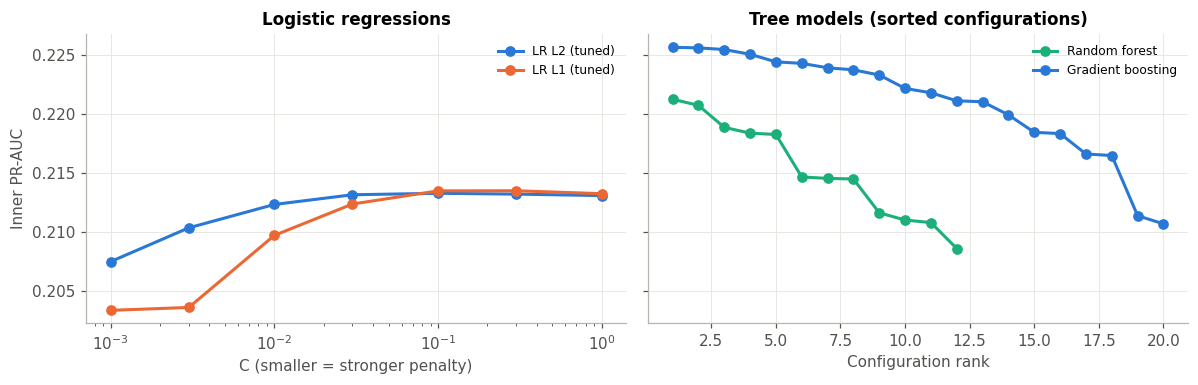

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for name, color in (("LR L2 (tuned)", BLUE), ("LR L1 (tuned)", ORANGE)):
    t = tuning_table[tuning_table["model"] == name]
    t = t.assign(C=[json.loads(p)["C"] for p in t["params"]]).sort_values("C")
    axes[0].plot(t["C"], t["inner PR-AUC"], "o-", color=color, linewidth=2, label=name)
axes[0].set(xscale="log", xlabel="C (smaller = stronger penalty)", ylabel="Inner PR-AUC", title="Logistic regressions")
axes[0].legend(frameon=False, fontsize=8)
for name, color in (("Random forest", AQUA), ("Gradient boosting", BLUE)):
    v = tuning_table.loc[tuning_table["model"] == name, "inner PR-AUC"].to_numpy()
    axes[1].plot(np.arange(1, len(v) + 1), v, "o-", color=color, linewidth=2, label=name)
axes[1].set(xlabel="Configuration rank", title="Tree models (sorted configurations)")
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

**Reading the tuning results**

* **Logistic regressions:** performance is flat for `C` between 0.03 and 1 (inner PR-AUC 0.212 to 0.213) and drops only with a very strong penalty. The default `C = 1` of week 2 was already close to the best value.
* **Tree models:** the choice of configuration matters more (0.209 to 0.221 for the forest, 0.211 to 0.226 for boosting). For boosting, the best configurations use a subset of features per split (`max_features = 0.6`); the two lowest scores come from `max_features = 1.0`.
* **Stability:** the top boosting configurations are almost tied (0.2256, 0.2256 and 0.2254), so the exact choice varies with the outer fold (3 different boosting configurations, 2 forest configurations). We do not interpret individual hyperparameter values.
* **Limits of the search:** only 12 of 60 forest configurations and 20 of 972 boosting configurations were sampled. Some selected values lie at the edge of their grid (`learning_rate`, `max_iter` and `max_leaf_nodes` for boosting, `max_features` for the forest), so a slightly better configuration may exist outside it.

## 4. Results

### 4.1 Outer evaluation of every model

In [7]:
def tuned_model(name, fold):
    return make_model(clone(CLASSIFIERS[name]).set_params(**SEARCH_SPACE[name][best_by_fold[name][fold]]))


for name in CLASSIFIERS:
    results[name], oof_scores[name], train_scores[name] = evaluate_cv(lambda f, name=name: tuned_model(name, f))

# Soft voting: plain mean of the probabilities, members fixed in advance, nothing learned on validation folds
MEMBERS = ["LR L1 (tuned)", "Random forest", "Gradient boosting"]
ENSEMBLE = "Soft-voting ensemble"
oof_scores[ENSEMBLE] = np.mean([oof_scores[m] for m in MEMBERS], axis=0)
train_scores[ENSEMBLE] = {f: np.mean([train_scores[m][f] for m in MEMBERS], axis=0) for f in FOLDS}
results[ENSEMBLE] = pd.DataFrame([
    {"fold": f, **compute_metrics(y[folds == f], oof_scores[ENSEMBLE][folds == f]),
     "Train PR-AUC": average_precision_score(y[folds != f], train_scores[ENSEMBLE][f]),
     "Fit time (s)": sum(results[m].loc[f, "Fit time (s)"] for m in MEMBERS)} for f in FOLDS]).set_index("fold")

METRICS = list(results[BASELINE].columns)
summary = pd.concat({n: r[METRICS].agg(["mean", "std"]).T for n, r in results.items()}, axis=1)
summary.to_csv(OUT_DIR / "model_cv_results.csv")
pd.concat(results, names=["model"]).to_csv(OUT_DIR / "model_cv_results_by_fold.csv")
pretty = pd.DataFrame({m: {n: f"{r[m].mean():.3f} ± {r[m].std():.3f}" for n, r in results.items()} for m in METRICS})
display(pretty.sort_values("PR-AUC", ascending=False))

,PR-AUC,ROC-AUC,Precision@20%,Recall@20%,Accuracy,Balanced acc.,Precision@0.5,Recall@0.5,F1@0.5,Train PR-AUC,Fit time (s)
Gradient boosting,0.230 ± 0.004,0.674 ± 0.008,0.227 ± 0.006,0.396 ± 0.010,0.660 ± 0.014,0.622 ± 0.007,0.184 ± 0.006,0.572 ± 0.010,0.278 ± 0.007,0.284 ± 0.014,15.818 ± 6.945
Soft-voting ensemble,0.228 ± 0.003,0.676 ± 0.008,0.224 ± 0.006,0.392 ± 0.011,0.717 ± 0.007,0.622 ± 0.006,0.202 ± 0.006,0.499 ± 0.011,0.287 ± 0.007,0.328 ± 0.005,76.284 ± 13.837
Random forest,0.227 ± 0.005,0.673 ± 0.008,0.223 ± 0.007,0.389 ± 0.012,0.782 ± 0.005,0.605 ± 0.006,0.226 ± 0.008,0.376 ± 0.012,0.282 ± 0.009,0.517 ± 0.009,49.238 ± 6.623
LR L1 (tuned),0.215 ± 0.002,0.664 ± 0.007,0.215 ± 0.004,0.376 ± 0.008,0.670 ± 0.005,0.616 ± 0.007,0.183 ± 0.004,0.546 ± 0.014,0.274 ± 0.007,0.220 ± 0.001,11.228 ± 6.763
LR baseline (week 2),0.214 ± 0.002,0.663 ± 0.007,0.215 ± 0.004,0.376 ± 0.007,0.668 ± 0.004,0.616 ± 0.008,0.183 ± 0.005,0.548 ± 0.015,0.274 ± 0.007,0.221 ± 0.001,7.996 ± 1.799
LR L2 (tuned),0.214 ± 0.002,0.664 ± 0.007,0.215 ± 0.006,0.376 ± 0.010,0.668 ± 0.004,0.616 ± 0.008,0.183 ± 0.005,0.548 ± 0.014,0.274 ± 0.007,0.220 ± 0.001,5.463 ± 0.856


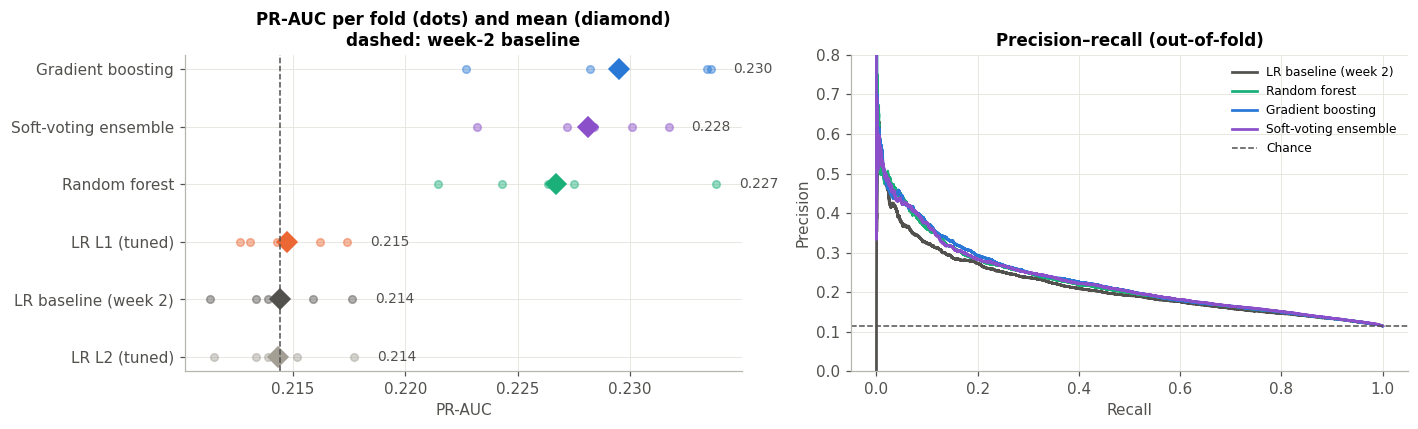

In [8]:
COLORS = {BASELINE: GRAY, "LR L2 (tuned)": "#a39f95", "LR L1 (tuned)": ORANGE, "Random forest": AQUA,
          "Gradient boosting": BLUE, ENSEMBLE: "#8a4fc9"}
order = sorted(results, key=lambda n: results[n]["PR-AUC"].mean())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
for pos, n in enumerate(order):
    v = results[n]["PR-AUC"]
    ax.plot(v, np.full(len(v), pos), "o", color=COLORS[n], alpha=0.45, markersize=5)
    ax.plot(v.mean(), pos, "D", color=COLORS[n], markersize=9)
    ax.text(v.max() + 0.001, pos, f"{v.mean():.3f}", va="center", fontsize=9, color=GRAY)
ax.axvline(results[BASELINE]["PR-AUC"].mean(), color=GRAY, linestyle="--", linewidth=1)
ax.set_yticks(range(len(order)), order)
ax.set(xlabel="PR-AUC", title="PR-AUC per fold (dots) and mean (diamond)\ndashed: week-2 baseline")
ax = axes[1]
for n in (BASELINE, "Random forest", "Gradient boosting", ENSEMBLE):
    prec, rec, _ = precision_recall_curve(y, oof_scores[n])
    ax.plot(rec[:-1], prec[:-1], color=COLORS[n], linewidth=1.8, label=n)
ax.axhline(prevalence, color=GRAY, linestyle="--", linewidth=1, label="Chance")
ax.set(xlabel="Recall", ylabel="Precision", ylim=(0, 0.8), title="Precision–recall (out-of-fold)")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

### 4.2 Over-fitting and amount of data

Left: gap between training and validation PR-AUC. Right: learning curve of the gradient boosting (final configuration) trained on a growing share of the training **patients**; does more data still help?

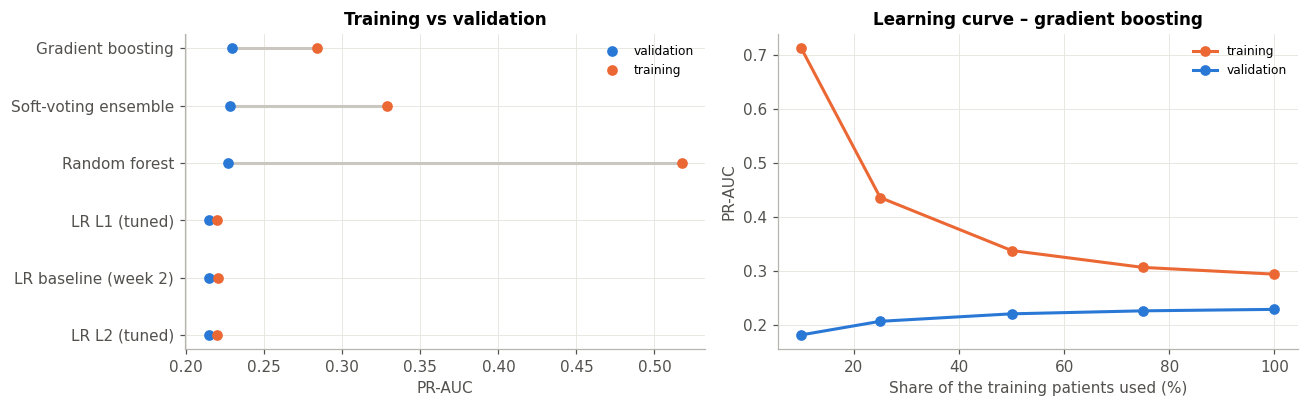

,Train PR-AUC,PR-AUC,gap
LR L2 (tuned),0.220,0.214,0.006
LR baseline (week 2),0.221,0.214,0.006
LR L1 (tuned),0.220,0.215,0.005
Random forest,0.517,0.227,0.291
Soft-voting ensemble,0.328,0.228,0.100
Gradient boosting,0.284,0.230,0.054


,train,validation
share,,
0.10,0.713,0.182
0.25,0.437,0.208
0.50,0.339,0.221
0.75,0.307,0.227
1.00,0.295,0.230


In [9]:
def learning_point(share, fold):
    tr = train.index[folds != fold]
    patients = np.sort(train.loc[tr, "patient_nbr"].unique())
    kept = np.random.default_rng(SEED + int(fold)).permutation(patients)[:int(round(share * len(patients)))]
    idx = tr[train.loc[tr, "patient_nbr"].isin(kept)]
    model = make_model(clone(CLASSIFIERS["Gradient boosting"]).set_params(**final_params["Gradient boosting"]))
    model.fit(X.loc[idx], y[idx])
    va = folds == fold
    return {"share": share, "fold": fold,
            "train": average_precision_score(y[idx], model.predict_proba(X.loc[idx])[:, 1]),
            "validation": average_precision_score(y[va], model.predict_proba(X[va])[:, 1])}


SHARES = [0.1, 0.25, 0.5, 0.75, 1.0]
curve = pd.DataFrame([learning_point(s, f) for s in SHARES for f in FOLDS]).groupby("share")[["train", "validation"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
gap = pd.DataFrame({n: r[["Train PR-AUC", "PR-AUC"]].mean() for n, r in results.items()}).T.loc[order]
pos = np.arange(len(gap))
axes[0].hlines(pos, gap["PR-AUC"], gap["Train PR-AUC"], color="#c9c7bf", linewidth=2)
axes[0].plot(gap["PR-AUC"], pos, "o", color=BLUE, label="validation")
axes[0].plot(gap["Train PR-AUC"], pos, "o", color=ORANGE, label="training")
axes[0].set_yticks(pos, gap.index)
axes[0].set(xlabel="PR-AUC", title="Training vs validation")
axes[0].legend(frameon=False, fontsize=8)
axes[1].plot(curve.index * 100, curve["train"], "o-", color=ORANGE, linewidth=2, label="training")
axes[1].plot(curve.index * 100, curve["validation"], "o-", color=BLUE, linewidth=2, label="validation")
axes[1].set(xlabel="Share of the training patients used (%)", ylabel="PR-AUC", title="Learning curve – gradient boosting")
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()
display(gap.assign(gap=gap["Train PR-AUC"] - gap["PR-AUC"]).round(3))
display(curve.round(3))

### 4.3 Does class weighting matter?

`class_weight="balanced"` is kept from week 2. Here the gradient boosting (final configuration) is compared with and without it, also on the **Brier score** (quality of the probabilities, lower is better).

In [10]:
rows = {}
for label, cw in (("balanced", "balanced"), ("no weighting", None)):
    r, oof, _ = evaluate_cv(lambda f, cw=cw: make_model(clone(CLASSIFIERS["Gradient boosting"]).set_params(
        **final_params["Gradient boosting"], class_weight=cw)))
    rows[label] = {**r[["PR-AUC", "ROC-AUC", "Recall@20%", "Recall@0.5"]].mean(),
                   "Brier": brier_score_loss(y, oof), "mean predicted risk": oof.mean()}
    if cw is None:
        oof_unweighted = oof
weighting = pd.DataFrame(rows).T
print(f"Reference: Brier of the constant prediction {prevalence:.3f} = {prevalence * (1 - prevalence):.4f}")
display(weighting.round(4))

Reference: Brier of the constant prediction 0.114 = 0.1013


,PR-AUC,ROC-AUC,Recall@20%,Recall@0.5,Brier,mean predicted risk
balanced,0.2296,0.6743,0.397,0.5681,0.2144,0.4478
no weighting,0.2332,0.6758,0.396,0.0064,0.0961,0.1139


**Reading the results**

* **Ranking:** gradient boosting (PR-AUC 0.230), soft voting (0.228) and random forest (0.227) are ahead of the logistic regressions (0.214 to 0.215). At the 20 % capacity, boosting reaches a recall of 39.6 % and a precision of 22.7 % (baseline: 37.6 % and 21.5 %).
* **Tuning a logistic regression brings nothing** (0.214 and 0.215 against 0.214): the gain comes from the tree models, which can represent non-linearities and interactions.
* **Over-fitting:** the forest has a very large gap (training 0.517, validation 0.227), boosting a moderate one (0.284 against 0.230). The logistic regressions hardly over-fit (gap about 0.006), which suggests that they are limited by bias. A gap alone does not make a model worse: the validation score decides.
* **Amount of data:** from 75 % to 100 % of the patients, validation PR-AUC only goes from 0.227 to 0.230. More patients of the same kind would probably bring little; more informative variables are a more promising direction.
* **Class weighting:** without weights, boosting has a slightly higher PR-AUC (0.233 against 0.230), practically the same recall at 20 % (39.6 % against 39.7 %) and much better probabilities (Brier 0.096 against 0.214; constant prediction 0.101). With weights the mean predicted risk is 0.448 for a prevalence of 0.114, so these scores are only usable as a **ranking**. Without weights the threshold 0.5 is useless (recall 0.6 %) and has to be replaced by the top-20 % rule.

The learning curve and the weighting comparison use the final configuration, chosen with all 5 folds. Their scores are therefore not strictly nested; the effect looks small (0.2296 against 0.2295 nested). We keep the balanced model here, as planned in section 2, and leave the weighting choice to week 4.

## 5. Comparison with the baseline

Each model and the baseline are evaluated on the same folds, so we compare them fold by fold. The training sets of the folds overlap, so a plain paired t-test is over-confident; we use the **corrected resampled t-test** of Nadeau & Bengio (2003), where the variance is multiplied by $\frac1k+\frac{n_{val}}{n_{train}}$ instead of $\frac1k$. With 5 folds this stays a rough indication, and we apply a Holm correction because five models are tested.

In [11]:
def corrected_ttest(diff):
    k = len(diff)
    se = np.sqrt(diff.var(ddof=1) * (1 / k + 1 / (k - 1)))   # n_val / n_train = 1 / (k - 1)
    half = stats.t.ppf(0.975, k - 1) * se
    return diff.mean() - half, diff.mean() + half, 2 * stats.t.sf(abs(diff.mean()) / se, k - 1)


def caught(name):
    return int(y[flag_per_fold(oof_scores[name])].sum())


base = results[BASELINE]
rows = {}
for n in [m for m in results if m != BASELINE]:
    d = results[n]["PR-AUC"] - base["PR-AUC"]
    low, high, p = corrected_ttest(d)
    rows[n] = {"PR-AUC": results[n]["PR-AUC"].mean(), "gain": d.mean(), "gain (%)": 100 * d.mean() / base["PR-AUC"].mean(),
               "95 % CI low": low, "95 % CI high": high, "folds won": int((d > 0).sum()), "p": p,
               "caught@20%": caught(n), "extra vs baseline": caught(n) - caught(BASELINE)}
comparison = pd.DataFrame(rows).T.sort_values("PR-AUC", ascending=False)
ranked = comparison["p"].sort_values()
comparison["p (Holm)"] = np.minimum(1, (ranked * np.arange(len(ranked), 0, -1)).cummax())
comparison.to_csv(OUT_DIR / "comparison_with_baseline.csv")
print(f"Early readmissions caught by the baseline (top 20 %): {caught(BASELINE):,} of {y.sum():,}")
display(comparison.round(4))

d = results[ENSEMBLE]["PR-AUC"] - results["Gradient boosting"]["PR-AUC"]
low, high, p = corrected_ttest(d)
print(f"Ensemble - gradient boosting: {d.mean():+.4f} [{low:+.4f}, {high:+.4f}], p = {p:.3f}, folds won {int((d > 0).sum())}/5")

Early readmissions caught by the baseline (top 20 %): 3,419 of 9,098


,PR-AUC,gain,gain (%),95 % CI low,95 % CI high,folds won,p,caught@20%,extra vs baseline,p (Holm)
Gradient boosting,0.2295,0.0151,7.0436,0.0089,0.0213,5.0,0.0025,3606.0,187.0,0.0098
Soft-voting ensemble,0.2281,0.0137,6.3867,0.0088,0.0186,5.0,0.0015,3566.0,147.0,0.0075
Random forest,0.2267,0.0123,5.7235,0.0034,0.0211,5.0,0.0182,3542.0,123.0,0.0547
LR L1 (tuned),0.2147,0.0003,0.1448,-0.0009,0.0015,3.0,0.5129,3423.0,4.0,1.0000
LR L2 (tuned),0.2143,-0.0001,-0.0397,-0.0007,0.0006,3.0,0.7379,3418.0,-1.0,1.0000


Ensemble - gradient boosting: -0.0014 [-0.0057, +0.0029], p = 0.416, folds won 2/5


**Reading the comparison**

* **Gradient boosting** improves the PR-AUC by 0.0151 (+7.0 %, 95 % CI [0.0089, 0.0213]), wins on 5 folds out of 5 and remains significant after Holm correction (p = 0.010). With the same number of flagged encounters, it catches **187 more early readmissions** (3,606 against 3,419, of 9,098).
* **Soft voting** is also significantly better than the baseline (+6.4 %, corrected p = 0.007), but not better than boosting alone (difference -0.0014, CI [-0.0057, +0.0029], p = 0.42, 2 folds won). It costs about 5 times more to train: we do not keep it.
* **Random forest** wins on 5 folds (+5.7 %), but its corrected p-value (0.055) is just above 5 %: the gain is likely but not established at this level.
* **Tuned logistic regressions** are indistinguishable from the baseline.

**Choice for the rest of the notebook: gradient boosting**, which has the best mean PR-AUC and is simpler than the ensemble. The gain is real but modest, and with 5 folds the p-values and intervals are only indicative.

## 6. Feature selection

Second research question: *which variables are useful, and is a smaller set enough?* Three families are compared. Each works on the **43 original variables** (not on one-hot columns, so that "15 variables" means 15 things to collect) and uses **only the outer training folds**:

| Family | Method |
| --- | --- |
| **Filter** | Mutual information between each variable and the target (numerical variables cut into training-fold deciles). Fast, ignores redundancy and the model. |
| **Wrapper** | Forward selection: at each step, add the variable that most improves the PR-AUC of a small gradient boosting on inner validation folds (2 inner splits), up to 15 variables. Accounts for redundancy; expensive. |
| **Embedded** | L1 logistic regression (C = 0.1): a variable is ranked by the sum of \|coefficient\| × column standard deviation. |

The top *k* variables of each fold's own ranking then train the gradient boosting (final configuration) and the logistic regression, evaluated on the outer validation fold.

**Rule fixed in advance:** a subset is "as good as" the full set if its mean PR-AUC is at most **0.005** below that of the same model with 43 variables.

The gradient boosting configuration comes from section 3, where all 5 folds contributed; it is the same for all subsets, but it was tuned on 43 variables, so small subsets may be slightly disadvantaged.

In [13]:
import joblib


def rank_filter(tr):
    scores = {}
    for c in FEATURES:
        if c in NUMERIC:
            v = pd.qcut(X.loc[tr, c], 10, labels=False, duplicates="drop")
        else:
            v = pd.factorize(X.loc[tr, c].fillna("Unknown"))[0]
        scores[c] = mutual_info_score(v, y[tr])
    return pd.Series(scores).sort_values(ascending=False).index.tolist()


def rank_embedded(tr):
    prep = make_preprocess().fit(X.loc[tr])
    Z = prep.transform(X.loc[tr])
    clf = clone(CLASSIFIERS["LR L1 (tuned)"]).set_params(C=0.1).fit(Z, y[tr])
    weight = pd.Series(np.abs(clf.coef_[0]) * Z.std(axis=0), index=prep.get_feature_names_out())
    owner = {}
    for col in weight.index:                    # "cat__diag_1_group_Diabetes" -> diag_1_group
        name = col.split("__", 1)[1]
        owner[col] = max((c for c in FEATURES if name == c or name.startswith(c + "_")), key=len)
    return weight.groupby(owner).sum().reindex(FEATURES, fill_value=0).sort_values(ascending=False).index.tolist()


def wrapper_score(features, splits):
    score = 0
    for tr, va in splits:
        small = HistGradientBoostingClassifier(max_iter=60, learning_rate=0.1, max_leaf_nodes=7, min_samples_leaf=100,
                                               class_weight="balanced", early_stopping=False, random_state=SEED)
        m = make_model(small, features).fit(X.loc[tr], y[tr])
        score += average_precision_score(y[va], m.predict_proba(X.loc[va])[:, 1]) / len(splits)
    return score


def rank_wrapper(outer, k_max=15):
    inner = [f for f in FOLDS if f != outer][:2]
    splits = [(np.flatnonzero((folds != outer) & (folds != f)), np.flatnonzero(folds == f)) for f in inner]
    chosen, done, start = [], 0, time.perf_counter()
    total = sum(len(FEATURES) - s for s in range(k_max))
    with Parallel(n_jobs=4, return_as="generator") as pool:
        while len(chosen) < k_max:
            left = [c for c in FEATURES if c not in chosen]
            scores = []
            for s in pool(delayed(wrapper_score)(chosen + [c], splits) for c in left):
                scores.append(s)
                done += 1
                elapsed = time.perf_counter() - start
                print(f"\rfold {outer} | step {len(chosen) + 1}/{k_max} | {done}/{total} | {elapsed / 60:.1f} min elapsed | "
                      f"~{elapsed / done * (total - done) / 60:.1f} min left in this fold   ", end="", flush=True)
            chosen.append(left[int(np.argmax(scores))])
            print(f"\n  + {chosen[-1]} (PR-AUC {max(scores):.4f})", flush=True)
    return chosen


RANK_FILE = OUT_DIR / "rankings.joblib"
rankings = joblib.load(RANK_FILE) if RANK_FILE.exists() else {"filter": {}, "wrapper": {}, "embedded": {}}
for f in FOLDS:
    if f in rankings["wrapper"]:
        continue
    start, tr = time.perf_counter(), np.flatnonzero(folds != f)
    rankings["filter"][f] = rank_filter(tr)
    rankings["embedded"][f] = rank_embedded(tr)
    rankings["wrapper"][f] = rank_wrapper(f)
    joblib.dump(rankings, RANK_FILE)
    print(f"fold {f}: {time.perf_counter() - start:.0f} s", flush=True)

fold 0 | step 1/15 | 43/540 | 0.6 min elapsed | ~7.4 min left in this fold    
  + number_inpatient (PR-AUC 0.1773)
fold 0 | step 2/15 | 85/540 | 1.3 min elapsed | ~6.9 min left in this fold   
  + discharge_disposition_id (PR-AUC 0.2055)
fold 0 | step 3/15 | 126/540 | 2.7 min elapsed | ~8.9 min left in this fold   
  + medical_specialty (PR-AUC 0.2149)
fold 0 | step 4/15 | 166/540 | 4.8 min elapsed | ~10.7 min left in this fold   
  + number_diagnoses (PR-AUC 0.2191)
fold 0 | step 5/15 | 205/540 | 6.5 min elapsed | ~10.7 min left in this fold   
  + payer_code (PR-AUC 0.2214)
fold 0 | step 6/15 | 243/540 | 7.8 min elapsed | ~9.6 min left in this fold    
  + num_medications (PR-AUC 0.2224)
fold 0 | step 7/15 | 280/540 | 9.1 min elapsed | ~8.4 min left in this fold   
  + max_glu_serum (PR-AUC 0.2225)
fold 0 | step 8/15 | 316/540 | 10.3 min elapsed | ~7.3 min left in this fold   
  + age_years (PR-AUC 0.2231)
fold 0 | step 9/15 | 351/540 | 11.5 min elapsed | ~6.2 min left in this fold 

Gradient boosting: 9/20 | wrapper, k=3 | 58 s
Gradient boosting: 10/20 | wrapper, k=5 | 100 s
Gradient boosting: 11/20 | wrapper, k=8 | 97 s
Gradient boosting: 12/20 | wrapper, k=10 | 97 s
Gradient boosting: 13/20 | wrapper, k=15 | 142 s
Gradient boosting: 14/20 | embedded, k=3 | 74 s
Gradient boosting: 15/20 | embedded, k=5 | 114 s
Gradient boosting: 16/20 | embedded, k=8 | 144 s
Gradient boosting: 17/20 | embedded, k=10 | 140 s
Gradient boosting: 18/20 | embedded, k=15 | 177 s
Gradient boosting: 19/20 | embedded, k=20 | 163 s
Gradient boosting: 20/20 | embedded, k=30 | 181 s
Logistic regression: 1/20 | all features, k=43 | 40 s
Logistic regression: 2/20 | filter, k=3 | 5 s
Logistic regression: 3/20 | filter, k=5 | 6 s
Logistic regression: 4/20 | filter, k=8 | 9 s
Logistic regression: 5/20 | filter, k=10 | 12 s
Logistic regression: 6/20 | filter, k=15 | 15 s
Logistic regression: 7/20 | filter, k=20 | 19 s
Logistic regression: 8/20 | filter, k=30 | 34 s
Logistic regression: 9/20 | wrap

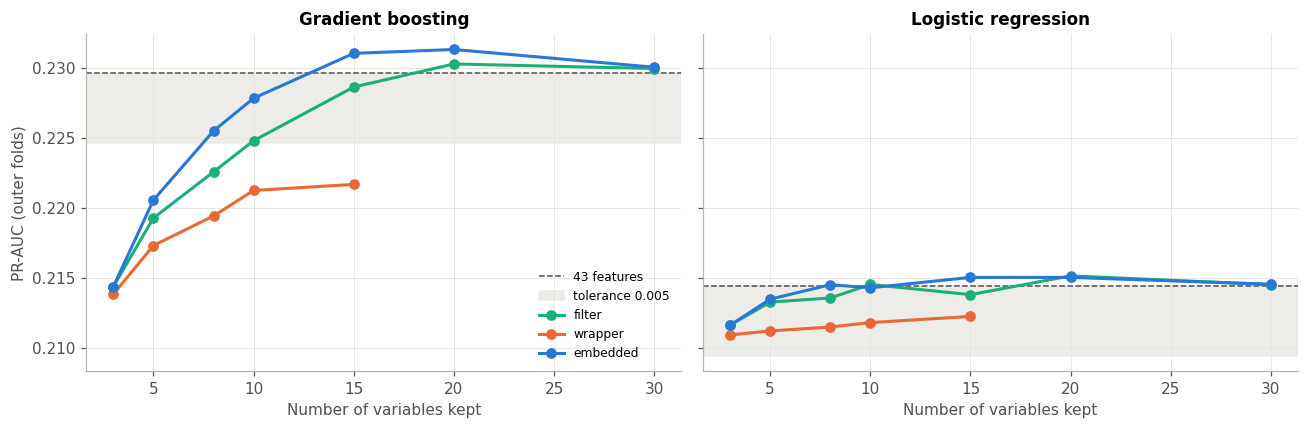

k                                    3      5      8      10     15     20  \
model               method                                                   
Gradient boosting   all features    NaN    NaN    NaN    NaN    NaN    NaN   
                    embedded      0.214  0.221  0.225  0.228  0.231  0.231   
                    filter        0.214  0.219  0.223  0.225  0.229  0.230   
                    wrapper       0.214  0.217  0.219  0.221  0.222    NaN   
Logistic regression all features    NaN    NaN    NaN    NaN    NaN    NaN   
                    embedded      0.212  0.213  0.215  0.214  0.215  0.215   
                    filter        0.212  0.213  0.214  0.215  0.214  0.215   
                    wrapper       0.211  0.211  0.211  0.212  0.212    NaN   

k                                    30     43  
model               method                      
Gradient boosting   all features    NaN  0.230  
                    embedded      0.230    NaN  
                    filter        0.230    NaN  
                    wrapper         NaN    NaN  
Logistic regression all features    NaN  0.214  
                    embedded      0.215    NaN  
                    filter        0.215    NaN  
                    wrapper         NaN    NaN

,model,method,full PR-AUC,smallest k,PR-AUC at k
0,Gradient boosting,filter,0.2296,10.0,0.2248
1,Gradient boosting,wrapper,0.2296,NaN,NaN
2,Gradient boosting,embedded,0.2296,8.0,0.2255
3,Logistic regression,filter,0.2144,3.0,0.2116
4,Logistic regression,wrapper,0.2144,3.0,0.2109
5,Logistic regression,embedded,0.2144,3.0,0.2116


In [16]:
K_GRID = [3, 5, 8, 10, 15, 20, 30]
TOLERANCE = 0.005
fs_models = {"Gradient boosting": clone(CLASSIFIERS["Gradient boosting"]).set_params(**final_params["Gradient boosting"]),
             "Logistic regression": baseline_clf}
FS_FILE = OUT_DIR / "fs_rows.joblib"
if FS_FILE.exists():
    rows = joblib.load(FS_FILE)
elif "rows" not in globals() or not isinstance(rows, list):
    rows = []
# keep each (model, method, k, fold) once
rows = list({(r["model"], r["method"], r["k"], r["fold"]): r for r in rows}.values())
done = {(r["model"], r["method"], r["k"]) for r in rows}

for model_name, clf in fs_models.items():
    runs = {("all features", len(FEATURES)): lambda f: FEATURES}
    for method, by_fold in rankings.items():
        for k in (k for k in K_GRID if k <= len(by_fold[FOLDS[0]])):
            runs[(method, k)] = lambda f, by_fold=by_fold, k=k: by_fold[f][:k]
    for n, ((method, k), subset) in enumerate(runs.items(), 1):
        if (model_name, method, k) in done:
            continue
        start = time.perf_counter()
        r, _, _ = evaluate_cv(lambda f: make_model(clone(clf), subset(f)))
        rows += [{"model": model_name, "method": method, "k": k, "fold": f, "PR-AUC": r.loc[f, "PR-AUC"]} for f in FOLDS]
        joblib.dump(rows, FS_FILE)
        print(f"{model_name}: {n}/{len(runs)} | {method}, k={k} | {time.perf_counter() - start:.0f} s", flush=True)
fs = pd.DataFrame(rows)
fs_summary = fs.groupby(["model", "method", "k"])["PR-AUC"].agg(["mean", "std"]).reset_index()
fs_summary.to_csv(OUT_DIR / "feature_selection_results.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
smallest = []
for ax, model_name in zip(axes, fs_models):
    s = fs_summary[fs_summary["model"] == model_name]
    full = s.loc[s["method"] == "all features", "mean"].item()
    ax.axhline(full, color=GRAY, linestyle="--", linewidth=1, label="43 features")
    ax.axhspan(full - TOLERANCE, full, color="#e6e5e0", alpha=0.7, label="tolerance 0.005")
    for method, color in (("filter", AQUA), ("wrapper", ORANGE), ("embedded", BLUE)):
        m = s[s["method"] == method]
        ax.plot(m["k"], m["mean"], "o-", color=color, linewidth=2, label=method)
        ok = m[m["mean"] >= full - TOLERANCE]
        smallest.append({"model": model_name, "method": method, "full PR-AUC": full,
                         "smallest k": ok["k"].min() if len(ok) else np.nan,
                         "PR-AUC at k": ok.loc[ok["k"].idxmin(), "mean"] if len(ok) else np.nan})
    ax.set(xlabel="Number of variables kept", title=model_name)
axes[0].set_ylabel("PR-AUC (outer folds)")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()
smallest = pd.DataFrame(smallest)
display(fs_summary.pivot_table(index=["model", "method"], columns="k", values="mean").round(3))
display(smallest.round(4))

### 6.1 Which variables are selected?

Number of folds (out of 5) in which each variable is in the top 10 of each method. A variable selected in 5/5 folds is a stable choice.

In [17]:
freq = pd.DataFrame({m: pd.Series(list(itertools.chain.from_iterable(r[:10] for r in by.values()))).value_counts()
                     for m, by in rankings.items()}).fillna(0).astype(int)
freq["total"] = freq.sum(axis=1)
freq = freq.sort_values("total", ascending=False)
freq.to_csv(OUT_DIR / "selected_features_top10.csv")
display(freq)
jaccard = {m: round(float(np.mean([len(set(a[:10]) & set(b[:10])) / len(set(a[:10]) | set(b[:10]))
                                   for a, b in itertools.combinations(by.values(), 2)])), 2) for m, by in rankings.items()}
print("Stability of the top 10 (mean Jaccard between folds):", jaccard)
print("Wrapper, order of selection per fold:")
for f, r in rankings["wrapper"].items():
    print(f"  fold {f}:", ", ".join(r[:8]))

,filter,wrapper,embedded,total
discharge_disposition_id,5,5,5,15
number_inpatient,5,5,5,15
payer_code,5,3,5,13
number_diagnoses,5,1,5,11
medical_specialty,5,1,5,11
diag_3_group,5,1,5,11
number_emergency,5,3,1,9
diag_1_group,0,4,5,9
diag_2_group,0,3,5,8
num_medications,5,2,0,7


Stability of the top 10 (mean Jaccard between folds): {'filter': 1.0, 'wrapper': 0.3, 'embedded': 0.87}
Wrapper, order of selection per fold:
  fold 0: number_inpatient, discharge_disposition_id, medical_specialty, number_diagnoses, payer_code, num_medications, max_glu_serum, age_years
  fold 1: number_inpatient, discharge_disposition_id, age_years, admission_source_id, number_emergency, A1Cresult, diag_3_group, time_in_hospital
  fold 2: number_inpatient, discharge_disposition_id, diag_1_group, diag_2_group, number_emergency, race, glyburide-metformin, chlorpropamide
  fold 3: number_inpatient, discharge_disposition_id, diag_1_group, diag_2_group, admission_type_id, gender, age_years, time_in_hospital
  fold 4: number_inpatient, discharge_disposition_id, num_medications, number_emergency, admission_source_id, diag_2_group, diag_1_group, A1Cresult


### 6.2 What does the gradient boosting use?

Permutation importance on the **validation** folds: loss of PR-AUC when one variable is shuffled (mean of 5 folds). Correlated variables share their importance, and this is not a causal effect.

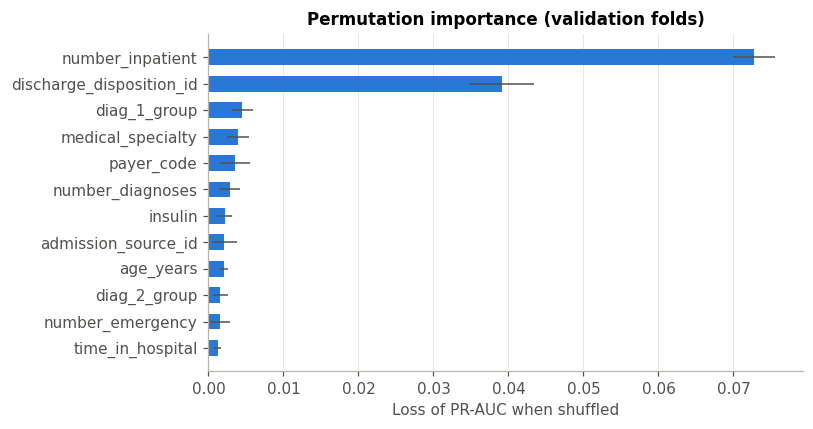

,mean,std
number_inpatient,0.0727,0.0028
discharge_disposition_id,0.0391,0.0043
diag_1_group,0.0045,0.0014
medical_specialty,0.0039,0.0015
payer_code,0.0035,0.0020
number_diagnoses,0.0028,0.0014
insulin,0.0022,0.0010
admission_source_id,0.0021,0.0017
age_years,0.0021,0.0005
diag_2_group,0.0016,0.0010


Variables with a mean importance below 0.0005: 23 of 43


In [18]:
imp = []
for f in FOLDS:
    va = folds == f
    m = tuned_model("Gradient boosting", f).fit(X[~va], y[~va])
    r = permutation_importance(m, X[va], y[va], scoring="average_precision", n_repeats=3, random_state=SEED)
    imp.append(pd.Series(r.importances_mean, index=FEATURES))
imp = pd.concat(imp, axis=1)
imp_table = pd.DataFrame({"mean": imp.mean(axis=1), "std": imp.std(axis=1)}).sort_values("mean", ascending=False)
imp_table.to_csv(OUT_DIR / "permutation_importance.csv")
top = imp_table.head(12)[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh(top.index, top["mean"], xerr=top["std"], color=BLUE, height=0.6, error_kw={"ecolor": GRAY, "elinewidth": 1})
ax.set(xlabel="Loss of PR-AUC when shuffled", title="Permutation importance (validation folds)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()
display(imp_table.head(12).round(4))
print("Variables with a mean importance below 0.0005:", int((imp_table["mean"] < 0.0005).sum()), "of", len(imp_table))

**Reading the feature selection**

* **Two variables dominate:** `number_inpatient` (permutation importance 0.073) and `discharge_disposition_id` (0.039). The next one, `diag_1_group`, is at 0.005, and 23 of the 43 variables are below 0.0005. The two dominant variables are in the top 10 of the three methods in all 5 folds. These are associations, not causes.
* **A smaller set is enough** under the rule fixed in advance (loss of at most 0.005). Smallest number of variables (PR-AUC):

| Model | Filter | Wrapper | Embedded |
| --- | --- | --- | --- |
| Gradient boosting (43 variables: 0.2296) | 10 (0.2248) | not reached with 15 | **8 (0.2255)** |
| Logistic regression (43 variables: 0.2144) | 3 (0.2116) | 3 (0.2109) | 3 (0.2116) |

* **No loss with 15 to 20 embedded variables** for boosting: 0.2310 and 0.2313 against 0.2296. The difference is smaller than the fold-to-fold standard deviation (about 0.004), so we do not claim an improvement.
* **The embedded method is the best compromise:** effective and stable (mean Jaccard between the top 10 of the folds: 0.87). The filter is perfectly stable (1.00) but ignores redundancy and the model.
* **The wrapper is disappointing:** 0.222 with 15 variables and unstable (0.30). On its own inner folds it matches or beats the other methods (checked separately with 10 variables), but it is worse on the outer folds: it has over-fitted its two inner splits. In several folds the gain becomes almost zero after 6 to 10 variables; many of the next ones are rare medications that tie and are then chosen by list order. They must not be interpreted.

**Conclusion:** about 8 to 15 variables are enough. The models compared in section 5 all use the 43 variables.

## 7. Error analysis

We study the errors of the tuned **gradient boosting** (out-of-fold), in the operational setting: the 20 % highest-risk encounters **of each fold** are flagged.

* **False negative (FN):** early readmission not flagged.
* **False positive (FP):** flagged, but no readmission within 30 days.

The original label (`>30` / `NO`) is read back from the raw file, only to describe the errors. Results by sex and race are part of the week-4 fairness analysis.

In [19]:
MAIN = "Gradient boosting"
raw = pd.read_csv(ROOT / "diabetic_data.csv", usecols=["encounter_id", "readmitted"], keep_default_na=False)
err = train.merge(raw, on="encounter_id", how="left", validate="one_to_one")
assert (err["encounter_id"].to_numpy() == train["encounter_id"].to_numpy()).all()
del raw
err["score"], err["flagged"] = oof_scores[MAIN], flag_per_fold(oof_scores[MAIN])
err["outcome"] = np.select([err["flagged"] & (y == 1), err["flagged"], y == 1], ["TP", "FP", "FN"], "TN")
print(err["outcome"].value_counts().to_dict())

by_label = err.groupby("readmitted").agg(encounters=("flagged", "size"), flagged=("flagged", "mean")).loc[["<30", ">30", "NO"]]
display(by_label.assign(flagged=(by_label["flagged"] * 100).round(1)).rename(columns={"flagged": "flagged (%)"}))
fp_mix = err.loc[err["outcome"] == "FP", "readmitted"].value_counts(normalize=True)
neg_mix = err.loc[y == 0, "readmitted"].value_counts(normalize=True)
print("False positives by true label:", fp_mix.round(3).to_dict(), "| all negatives:", neg_mix.round(3).to_dict())
display(err.groupby("outcome")[NUMERIC].mean().T[["TP", "FN", "FP", "TN"]].round(2))

{'TN': 58139, 'FP': 12304, 'FN': 5492, 'TP': 3606}


,encounters,flagged (%)
readmitted,,
<30,9098,39.6
>30,28412,24.9
NO,42031,12.4


False positives by true label: {'>30': 0.575, 'NO': 0.425} | all negatives: {'NO': 0.597, '>30': 0.403}


outcome,TP,FN,FP,TN
age_years,65.52,67.69,67.27,65.27
time_in_hospital,5.13,4.52,5.18,4.15
num_lab_procedures,44.69,44.02,45.74,42.11
num_procedures,1.10,1.36,1.11,1.39
num_medications,17.80,16.28,17.68,15.48
number_outpatient,0.53,0.38,0.57,0.32
number_emergency,0.67,0.14,0.55,0.10
number_inpatient,2.57,0.33,2.13,0.22
number_diagnoses,7.84,7.59,7.97,7.23


encounters  early readmissions  rate (%)  \
prior inpatient visits 0         52968.0              4548.0      8.59   
                       1         15209.0              2032.0     13.36   
                       2          5856.0              1073.0     18.32   
                       3+         5508.0              1445.0     26.23   
age                    <40        4979.0               556.0     11.17   
                       40-59     21289.0              2133.0     10.02   
                       60-79     38084.0              4496.0     11.81   
                       80+       15189.0              1913.0     12.59   
discharge              home      48204.0              4521.0      9.38   
                       other     31337.0              4577.0     14.61   

                              flagged (%)  recall (%)  precision (%)  PR-AUC  \
prior inpatient visits 0             4.99       13.87          23.86    0.16   
                       1            21.02       32.68          20.77    0.21   
                       2            81.11       83.88          18.95    0.23   
                       3+           96.55       97.65          26.53    0.37   
age                    <40          20.29       51.44          28.32    0.31   
                       40-59        17.41       40.88          23.52    0.24   
                       60-79        20.39       39.01          22.59    0.23   
                       80+          22.56       36.28          20.25    0.20   
discharge              home         12.31       29.00          22.09    0.20   
                       other        31.83       50.14          23.01    0.26   

                              ROC-AUC  
prior inpatient visits 0         0.64  
                       1         0.60  
                       2         0.55  
                       3+        0.62  
age                    <40       0.76  
                       40-59     0.70  
                       60-79     0.66  
                       80+       0.62  
discharge              home      0.67  
                       other     0.65

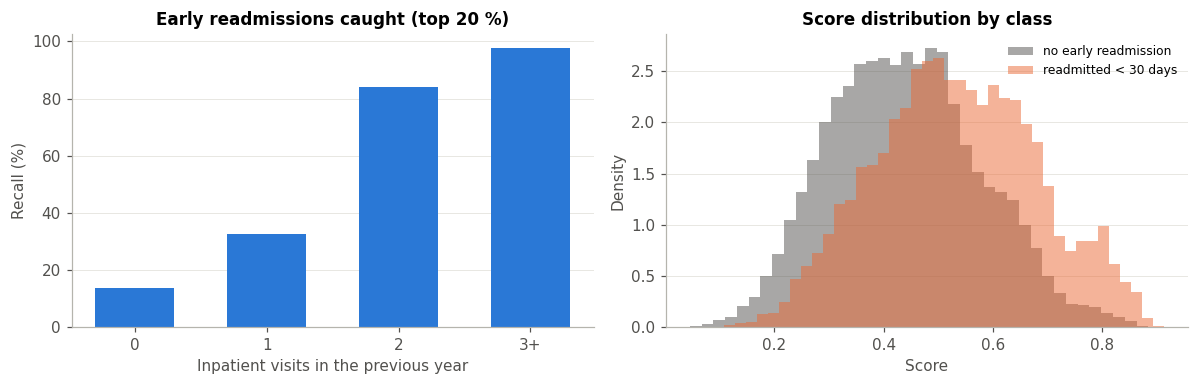

Share of the false negatives with no prior inpatient visit: 71.3%


In [20]:
def segment_row(g):
    return {"encounters": len(g), "early readmissions": int(g["target"].sum()), "rate (%)": 100 * g["target"].mean(),
            "flagged (%)": 100 * g["flagged"].mean(),
            "recall (%)": 100 * g.loc[g["target"] == 1, "flagged"].mean(),
            "precision (%)": 100 * g.loc[g["flagged"], "target"].mean(),
            "PR-AUC": average_precision_score(g["target"], g["score"]),
            "ROC-AUC": roc_auc_score(g["target"], g["score"])}


segments = {
    "prior inpatient visits": err["number_inpatient"].clip(upper=3).astype(int).astype(str).replace("3", "3+").to_numpy(),
    "age": np.asarray(pd.cut(err["age_years"], [0, 40, 60, 80, 100], labels=["<40", "40-59", "60-79", "80+"], right=False)),
    "discharge": np.where(err["discharge_disposition_id"] == "1", "home", "other"),
}
seg = pd.DataFrame({(name, level): segment_row(err[values == level])
                    for name, values in segments.items() for level in sorted(set(values), key=lambda s: (s != "<40", s))}).T
seg.to_csv(OUT_DIR / "error_analysis_segments.csv")
display(seg.round(2))

t = seg.loc["prior inpatient visits"]
fn_share0 = (err.loc[err["outcome"] == "FN", "number_inpatient"] == 0).mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(t.index, t["recall (%)"], color=BLUE, width=0.6)
axes[0].set(xlabel="Inpatient visits in the previous year", ylabel="Recall (%)", title="Early readmissions caught (top 20 %)")
axes[1].hist(err.loc[y == 0, "score"], bins=40, density=True, color=GRAY, alpha=0.5, label="no early readmission")
axes[1].hist(err.loc[y == 1, "score"], bins=40, density=True, color=ORANGE, alpha=0.5, label="readmitted < 30 days")
axes[1].set(xlabel="Score", ylabel="Density", title="Score distribution by class")
axes[1].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()
print(f"Share of the false negatives with no prior inpatient visit: {fn_share0:.1%}")

### 7.1 Do the models make the same mistakes? Are the scores usable as probabilities?

Overlap (Jaccard) of the missed early readmissions:


,LR baseline (week 2),Random forest,Gradient boosting
LR baseline (week 2),1.00,0.78,0.82
Random forest,0.78,1.00,0.86
Gradient boosting,0.82,0.86,1.00


Missed by all three models: 4,743 of 9,098 early readmissions (52.1%)


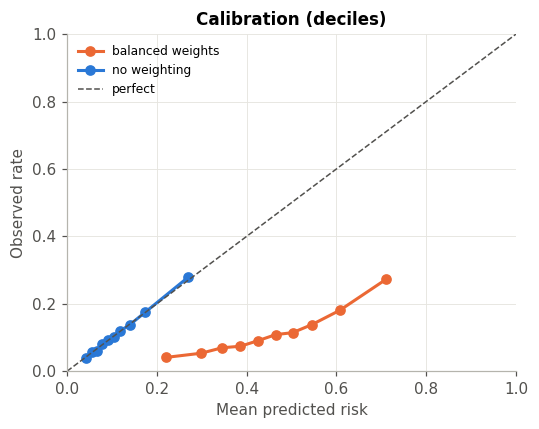

In [21]:
positive = y == 1
missed = {n: ~flag_per_fold(oof_scores[n]) & positive for n in (BASELINE, "Random forest", MAIN)}
overlap = pd.DataFrame({a: {b: (missed[a] & missed[b]).sum() / (missed[a] | missed[b]).sum() for b in missed} for a in missed})
print("Overlap (Jaccard) of the missed early readmissions:")
display(overlap.round(2))
all_missed = np.logical_and.reduce(list(missed.values())).sum()
print(f"Missed by all three models: {all_missed:,} of {positive.sum():,} early readmissions ({all_missed / positive.sum():.1%})")

fig, ax = plt.subplots(figsize=(5, 4))
for label, s, color in (("balanced weights", oof_scores[MAIN], ORANGE), ("no weighting", oof_unweighted, BLUE)):
    bins = pd.qcut(s, 10, labels=False, duplicates="drop")
    g = pd.DataFrame({"s": s, "y": y}).groupby(bins).mean()
    ax.plot(g["s"], g["y"], "o-", color=color, linewidth=2, label=label)
ax.plot([0, 1], [0, 1], color=GRAY, linestyle="--", linewidth=1, label="perfect")
ax.set(xlabel="Mean predicted risk", ylabel="Observed rate", title="Calibration (deciles)", xlim=(0, 1), ylim=(0, 1))
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

### 7.2 Leakage check on the selected model

Same test as in week 2: with permuted labels, the gradient boosting must fall back to chance.

In [22]:
y_shuffled = np.random.default_rng(SEED).permutation(y)
shuffled, _, _ = evaluate_cv(lambda f: make_model(clone(fs_models["Gradient boosting"])), y=y_shuffled)
print(f"Shuffled labels -> PR-AUC {shuffled['PR-AUC'].mean():.3f} (prevalence {prevalence:.3f}), "
      f"ROC-AUC {shuffled['ROC-AUC'].mean():.3f}")

Shuffled labels -> PR-AUC 0.115 (prevalence 0.114), ROC-AUC 0.499


**Reading the error analysis**

* **The model mostly recognises patients with a history of hospitalisation.** Recall is 97.6 % with 3 or more prior inpatient visits, 83.9 % with 2, 32.7 % with 1 and only **13.9 % with none**. Encounters without any prior visit account for 71.3 % of the false negatives, and for half of all early readmissions (4,548 of 9,098).
* **Within a group, the ranking is weak:** ROC-AUC is between 0.55 and 0.64 according to the number of prior visits, against 0.674 overall. Part of the global score comes from separating these groups.
* **The false positives are not random:** 57.5 % of them are readmitted later (> 30 days), against 40.3 % of all negatives. Part of the error comes from the 30-day cut-off.
* **Age and discharge:** recall falls from 51.4 % (under 40) to 36.3 % (80 and over), and is 50.1 % for non-home discharges against 29.0 % for home.
* **The models share their errors:** the cases missed by the baseline, the forest and boosting overlap strongly (Jaccard 0.78 to 0.86), and 52.1 % of the early readmissions are missed by all three. This suggests a limit of the available variables more than of the algorithm.
* **Leakage check:** with shuffled labels, PR-AUC is 0.115 (prevalence 0.114) and ROC-AUC 0.499: no sign of leakage. This test could not detect a variable that is known too late.

## 8. Conclusion and limitations

**What was achieved.** Gradient boosting reaches a PR-AUC of 0.230 ± 0.004, about twice the chance level (0.114), against 0.214 for the baseline, and catches 39.6 % of the early readmissions in the top 20 % (baseline 37.6 %). About 8 variables are enough to stay within 0.005 of the full model.

**What it means.** The gain is statistically supported but small. Among the flagged encounters, 22.7 % are true early readmissions and about 60 % of the early readmissions are still missed: the model can help to prioritise follow-up, not decide alone.

**Limitations**

* **Prediction time:** `discharge_disposition_id` is an important variable and is only known at discharge. The model is valid for a prediction made **at discharge**, not during the stay.
* **Forest tuning:** its configurations were compared with 100 trees to limit the computing time, then the selected ones were trained with 300. The ranking could differ slightly with 300 trees.
* **Configuration search:** small random search, some selected values at the edge of the grid (section 3).
* **Not strictly nested results:** the learning curve, the weighting comparison and the subset evaluation use the final configuration, chosen with the 5 folds.
* **Statistics:** 5 folds and overlapping training sets; p-values are indicative.
* **Data:** US hospital records from 1999 to 2008; performance on current patients is unknown.
* **Probabilities:** the balanced model is not calibrated; its scores are only a ranking.

**For week 4:** decide on the weighting and the calibration, choose the final variable set, study fairness by sex and race, and evaluate the final model **once** on the test set, which has not been used to train or evaluate any model so far.